# Revised DoE — recycle cycle 0–3 as a design factor (2026-10)

Agreed with the lab (Anupam, 2026-10-06):

* **Recycle cycles 0, 1, 2, 3** (0 = as extruded), treated as a whole-number design factor (recycle number enters the model as a numeric input).
* **~21 configurations**: 7 per polymer system (PP+PAL, HDPE+PAL, TPU+PAL).
* Each configuration is its own formulation (polymer, PAL %, extrusion temperature) taken to **one** recycle cycle.

**Design: a sliced Latin hypercube** — a Latin hypercube for each polymer's 7 runs, on the grid the lab sets:

* **PAL %** is cut into 21 thin bands grouped into 7 wide bands; every polymer takes one thin band in each wide band, so each polymer's
  7 runs cover the 7 wide bands once and the 21 runs cover the 21 thin bands once.
* **Temperature**: the 5 °C grid has only 13 settings, so every polymer takes one grid value in each of the 7 wide bands (polymers may share a value).
* **Recycle cycles** are balanced within each polymer and overall.

The arrangement is optimised on `discrepancy (all runs) + mean discrepancy (each polymer) + w × max |r|`, using only moves that keep this structure.

**Notebook layout**

1. **Design study** — how the design was chosen: the four space-filling metrics, a sweep of the correlation weight *w* with its Pareto front,
   and a comparison with Sobol, plain LHS and optimized LHS. **Selected: w = 0.02, seed 2.**
2. **The selected design** — the plan for the lab and its figures (design map, pair plot, correlation).
3. **Replicates and the specimen log** — 5 tensile specimens per configuration.
4. **Hand-off workbook.**

Logic in `utils/doe.py`, figures in `utils/plots.py`. **Nothing is written by default.** Each cell that can save has a `SAVE_*` switch and a name.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "utils").exists() and (ROOT.parent / "utils").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import config, io, doe, plots

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
p = config.paths(ROOT)

In [2]:
N_PER_POLYMER = 7                 # configurations per polymer system (3 polymers -> 21)
RECYCLE_CYCLES = (0, 1, 2, 3)     # 0 = as extruded, r = r recycling loops
N_SEEDS = 10                      # seeds per weight / per method in the study
PICK = (0.02, 2)                  # the selected design: (correlation weight w, seed), chosen in section 1

---
## 1 — Design study

Same check as the DMREF designs (`experiment03_hfo2_batch1_analysis`, §7): every candidate design is scored on four space-filling metrics in
the unit cube, **as fabricated** (1 % / 5 °C grid, integer cycle):

* **Centered L2 discrepancy** ↓ — global uniformity of coverage.
* **Min pairwise distance** ↑ — maximin: no two runs nearly duplicated.
* **Max |factor correlation|** ↓ — factor independence (confounding guard, threshold 0.3).
* **Fill distance** ↓ — the *largest hole*: the farthest any point of the space is from its nearest run (where GP predictions are weakest).

**Adjusted to this setup.** The polymer is categorical (the LVGP maps it to latent variables), so it is not a distance axis. Each metric is taken in
the (PAL %, temperature, cycle) cube twice: **all 21 runs with the polymer ignored**, and **within each polymer** (7 runs; the worst of the three).
The cycle is coded i / 3, and the fill-distance probe set keeps it on its four levels.

### 1.1 Correlation weight sweep — Pareto front

How much does penalising correlation cost? The sliced LHS is run with **w = 0, 0.005, 0.01, 0.02, 0.05, 0.1** (w = 0 is discrepancy only;
max |r| is the worst of the 3 factor pairs over all runs and each polymer), `N_SEEDS` seeds each. The table gives mean ± std per weight
(best in bold).

In [3]:
WEIGHTS = (0.0, 0.005, 0.01, 0.02, 0.05, 0.1)
SAVE_SWEEP = False                    # True -> write the per-design sweep metrics to doe/<SWEEP_NAME>.xlsx
SWEEP_NAME = "doe_v2_corr_weight_sweep"

sweep = doe.sweep_corr_weight(WEIGHTS, n_seeds=N_SEEDS)       # 60 designs, 2-10 min with machine load
sw_summary, sw_best = doe.method_summary(sweep.assign(method=[f"w = {w:g}" for w in sweep["corr_weight"]]))
sw_styled = sw_summary.T.style.apply(lambda _: np.where(sw_best.T, "font-weight: bold", ""), axis=None)
xlsx = io.save_path(p.doe, SWEEP_NAME, SAVE_SWEEP, ".xlsx")
if xlsx:
    with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
        sweep.to_excel(xw, sheet_name="per_design", index=False)
        sw_styled.to_excel(xw, sheet_name="summary")
sw_styled

method,w = 0,w = 0.005,w = 0.01,w = 0.02,w = 0.05,w = 0.1
all_discrepancy ↓,0.0215 ± 0.0002,0.0218 ± 0.0002,0.0219 ± 0.0004,0.0219 ± 0.0005,0.022 ± 0.0013,0.0216 ± 0.0014
all_min_dist ↑,0.1947 ± 0.0397,0.1677 ± 0.0605,0.1246 ± 0.037,0.1386 ± 0.0517,0.117 ± 0.0455,0.1156 ± 0.0443
all_max_corr ↓,0.0579 ± 0.0171,0.0372 ± 0.0153,0.03 ± 0.0162,0.0225 ± 0.0058,0.0136 ± 0.0061,0.0069 ± 0.0028
all_fill_dist ↓,0.4582 ± 0.0346,0.468 ± 0.0459,0.4766 ± 0.0296,0.4694 ± 0.0284,0.496 ± 0.0521,0.5271 ± 0.0468
poly_discrepancy ↓,0.0403 ± 0.0009,0.0408 ± 0.0007,0.0409 ± 0.0005,0.0407 ± 0.0013,0.0411 ± 0.0012,0.0411 ± 0.0012
poly_min_dist ↑,0.3773 ± 0.0853,0.3602 ± 0.082,0.3809 ± 0.0761,0.396 ± 0.0649,0.3912 ± 0.0523,0.3848 ± 0.0539
poly_max_corr ↓,0.2086 ± 0.0444,0.073 ± 0.0202,0.0614 ± 0.0261,0.0444 ± 0.0144,0.0267 ± 0.0086,0.0193 ± 0.0035
poly_fill_dist ↓,0.7374 ± 0.0309,0.7434 ± 0.0225,0.7348 ± 0.0285,0.7345 ± 0.0259,0.7281 ± 0.0267,0.7189 ± 0.0297
runs per polymer (7-7 = balanced),7-7,7-7,7-7,7-7,7-7,7-7
seeds with a polymer missing a cycle ↓,0,0,0,0,0,0


The worst within-polymer |r| (↓) against the two spacing metrics that move — fill distance (↓) and min pairwise distance (↑), all runs.
Small dots are single designs; large markers are the mean ± 1 std per weight; the dashed staircase is the **Pareto front of the single
designs** (no design beats a front point on both axes); the star is the **selected design**. One design is delivered, not an average, so the
front of single designs is what matters for the choice.

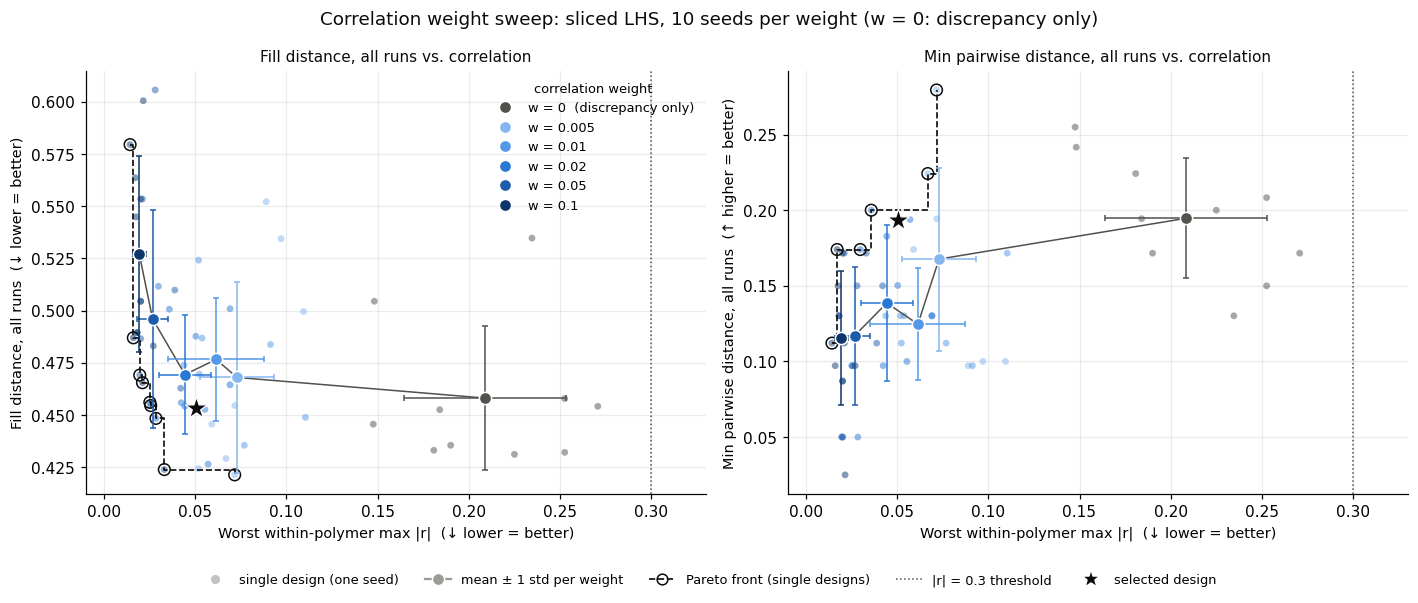

In [4]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_v2_corr_weight_pareto"

pick_design = doe.generate(f"Sliced LHS (CD + corr, w = {PICK[0]:g})", seed=PICK[1])
picked = doe.design_quality(pick_design)
plots.corr_weight_tradeoff(sweep, picked, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

**Shortlist.** The single designs no other design beats on all three at once (worst within-polymer |r| ↓, fill distance ↓, min distance ↑,
all runs), plus the first proposal (discrepancy only, w = 0, seed 42) for reference. The within-polymer columns are not part of the front;
they decided the pick.

In [5]:
first = doe.design_quality(doe.generate("Sliced LHS (CD only, w = 0)", seed=42))
cand = pd.concat([sweep.drop(columns="recycling_loops"),
                  pd.DataFrame([{**first, "corr_weight": 0.0, "seed": 42}])], ignore_index=True)
cand["role"] = ""
cand.loc[cand.index[-1], "role"] = "first proposal"
cand.loc[(cand["corr_weight"] == PICK[0]) & (cand["seed"] == PICK[1]), "role"] = "SELECTED"
cand["on_front"] = doe.pareto_mask(cand, minimize=["poly_max_corr", "all_fill_dist"], maximize=["all_min_dist"])
beats_first = ((cand["poly_max_corr"] < first["poly_max_corr"]) & (cand["all_fill_dist"] < first["all_fill_dist"])
               & (cand["all_min_dist"] > first["all_min_dist"])).sum()
print(f"selected design on the front: {bool(cand.loc[cand['role'] == 'SELECTED', 'on_front'].iloc[0])} · "
      f"designs better than the first proposal on all three: {beats_first} of {len(sweep)}")
show = ["role", "corr_weight", "seed", "poly_max_corr", "all_fill_dist", "all_min_dist", "all_discrepancy",
        "poly_discrepancy", "poly_fill_dist", "poly_min_dist"]
cand.loc[cand["on_front"] | (cand["role"] != ""), show].sort_values("poly_max_corr").round(4).reset_index(drop=True)

selected design on the front: True · designs better than the first proposal on all three: 13 of 60


,role,corr_weight,seed,poly_max_corr,all_fill_dist,all_min_dist,all_discrepancy,poly_discrepancy,poly_fill_dist,poly_min_dist
0,,0.100,6,0.0143,0.5795,0.1121,0.0194,0.0436,0.6903,0.4104
1,,0.100,8,0.0161,0.4870,0.0972,0.0231,0.0422,0.7457,0.3432
2,,0.100,2,0.0172,0.5636,0.1740,0.0199,0.0399,0.7380,0.3976
3,,0.100,3,0.0176,0.5449,0.1500,0.0196,0.0414,0.6899,0.2915
4,,0.050,5,0.0182,0.4895,0.1302,0.0223,0.0409,0.7483,0.4230
5,,0.100,5,0.0182,0.4895,0.1302,0.0223,0.0409,0.7483,0.4230
6,,0.050,4,0.0196,0.4692,0.0500,0.0228,0.0432,0.6900,0.4947
7,,0.100,9,0.0201,0.5534,0.1716,0.0221,0.0423,0.7589,0.3976
8,,0.100,7,0.0211,0.4655,0.1121,0.0219,0.0404,0.7026,0.3005
9,,0.020,0,0.0252,0.4561,0.0972,0.0217,0.0432,0.7559,0.4104


**Reading the sweep** (10 seeds per weight):

* **A small penalty does most of the work.** At w = 0.005 the worst within-polymer |r| drops from 0.21 to 0.07 on average (every seed ≤ 0.11),
  while the mean fill distance (0.458 → 0.468) and min distance (0.195 → 0.168) stay within the seed-to-seed spread. Beyond w ≈ 0.02 spacing
  pays for it: fill distance 0.50 at w = 0.05 and 0.53 at w = 0.1, min distance ≈ 0.12. The within-polymer metrics barely move with w.
* **No w = 0 design is on either front.** For every discrepancy-only design there is a penalised one with lower |r| and at least as good
  spacing; the first proposal (w = 0, seed 42) is beaten on all three by 13 of the 60 sweep designs.
* **The pick: w = 0.02, seed 2** — on the front, worst within-polymer |r| 0.050 (first proposal 0.270), all-runs fill distance 0.454 (0.475) and
  min distance 0.194 (0.174), within-polymer fill distance 0.703 (0.726) and discrepancy 0.0403 (0.0403); only the within-polymer min distance
  is lower (0.402 vs 0.456). It also needs 30 recycling loops instead of 33.

### 1.2 Comparison with Sobol, plain LHS and optimized LHS

**Sobol** (scrambled), **plain LHS** and **optimized LHS** (scipy random-CD, the August method) sample (polymer, PAL, temperature, cycle)
jointly in a 4-d cube, `N_SEEDS` seeds each. The **table** sets the **selected design** (one design, so no ±) against their means; the
**chart** shows the method means with the sliced LHS at the selected weight (the weight-sweep runs), and the star is the selected design.

In [6]:
SAVE_METRICS = False                  # True -> write the per-seed metrics to doe/<METRICS_NAME>.xlsx
METRICS_NAME = "doe_v2_method_metrics"

sliced_name = f"Sliced LHS (CD + corr, w = {PICK[0]:g})"
pick_name = f"{sliced_name}, seed {PICK[1]} (selected)"
base = doe.compare_methods(("Sobol", "Plain LHS", "Optimized LHS"), n_seeds=N_SEEDS)
tbl = pd.concat([base, sweep[sweep["corr_weight"] == PICK[0]].drop(columns=["corr_weight", "recycling_loops"])
                 .assign(method=sliced_name)], ignore_index=True)          # sliced LHS at the selected weight: the sweep runs
tbl_pick = pd.concat([base, pd.DataFrame([{"method": pick_name, "seed": PICK[1], **picked}])], ignore_index=True)
summary, best = doe.method_summary(tbl_pick)          # bold = best per row; ties all bold
styled = summary.T.style.apply(lambda _: np.where(best.T, "font-weight: bold", ""), axis=None)
xlsx = io.save_path(p.doe, METRICS_NAME, SAVE_METRICS, ".xlsx")
if xlsx:
    with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
        tbl.to_excel(xw, sheet_name="per_seed", index=False)
        styled.to_excel(xw, sheet_name="summary")          # bold carries over to Excel
styled

method,Sobol,Plain LHS,Optimized LHS,"Sliced LHS (CD + corr, w = 0.02), seed 2 (selected)"
all_discrepancy ↓,0.0242 ± 0.0027,0.0238 ± 0.0034,0.0198 ± 0.0017,0.0218
all_min_dist ↑,0.1819 ± 0.0656,0.1102 ± 0.0288,0.1473 ± 0.0489,0.1938
all_max_corr ↓,0.2139 ± 0.0683,0.2935 ± 0.1436,0.1087 ± 0.0482,0.025
all_fill_dist ↓,0.4841 ± 0.0357,0.5739 ± 0.098,0.4676 ± 0.0254,0.4535
poly_discrepancy ↓,0.0976 ± 0.0403,0.1309 ± 0.0335,0.0653 ± 0.0118,0.0403
poly_min_dist ↑,0.2634 ± 0.0744,0.1637 ± 0.0762,0.3486 ± 0.0679,0.4017
poly_max_corr ↓,0.6787 ± 0.1837,0.7239 ± 0.0971,0.5481 ± 0.1953,0.0504
poly_fill_dist ↓,0.9029 ± 0.1187,0.9472 ± 0.0683,0.7881 ± 0.042,0.703
runs per polymer (7-7 = balanced),"5-8, 6-8, 6-9, 7-7",7-7,7-7,7-7
seeds with a polymer missing a cycle ↓,5,8,1,0


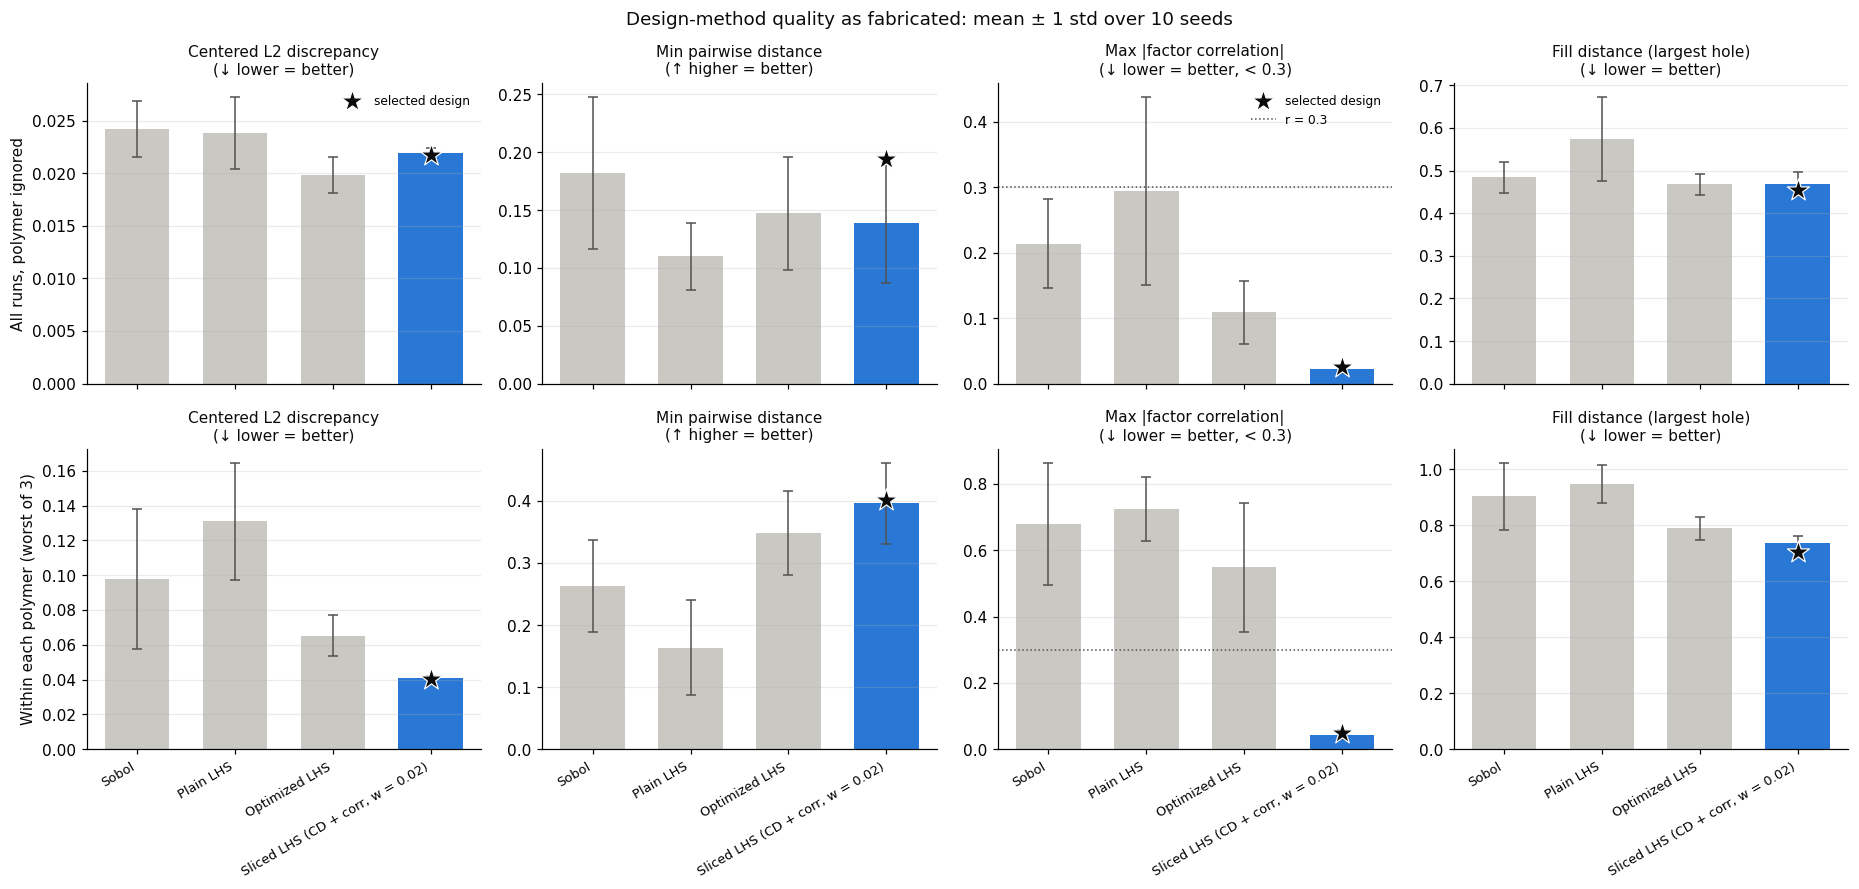

In [7]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_v2_method_comparison"

plots.design_method_comparison(tbl, picked, used_method=sliced_name,
                               save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

**Reading the comparison**:

* **The selected design wins every row of the table but one**: lowest |r| (0.050 within polymer vs 0.55–0.72 for the means of the joint
  designs), best fill distance (0.454 all runs, 0.703 within polymer), best min distance (0.194 / 0.402) and within-polymer discrepancy
  (0.0403 vs 0.065–0.131). Only the all-runs discrepancy is lower for optimized LHS (0.0198 vs 0.0218), which optimises exactly that.
* **As a method (chart, 10-seed means)**, the sliced LHS at w = 0.02 beats the joint designs on every within-polymer metric and on correlation;
  over all runs it matches optimized LHS on fill distance (0.469 vs 0.468), with a slightly lower min distance (0.139 vs 0.147). The joint designs
  only control the 21 runs together, so one polymer's 7 runs can bunch up.
* **Balance**: Sobol gives 5–9 runs per polymer, and Sobol / plain LHS often leave a polymer without one of the cycles; the sliced LHS always
  has 7 / 7 / 7 and every cycle in every polymer.

---
## 2 — The selected design (for the lab)

Sliced LHS with correlation weight **w = 0.02, seed 2**. These are the 21 configurations in the hand-off workbook, and the figures below are
the ones to share with the lab.

In [8]:
design, quality = doe.sliced_lhs(N_PER_POLYMER, recycle_cycles=RECYCLE_CYCLES, corr_weight=PICK[0], seed=PICK[1])
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in quality.items()})
print(f"correlation check (|r| < 0.3): all runs {quality['max_abs_corr']:.3f}, worst polymer {quality['max_abs_corr_slices']:.3f}")
design

{'n_configurations': 21, 'per_cycle': {0: 6, 1: 5, 2: 5, 3: 5}, 'cd_pooled': 0.0098, 'cd_slices': 0.0241, 'max_abs_corr': 0.025, 'max_abs_corr_slices': 0.0504, 'objective': 0.0348, 'objective_random_start': 0.0612, 'recycling_loops': 30, 'distinct_temps_per_polymer': {'HDPE+PAL': 7, 'PP+PAL': 7, 'TPU+PAL': 7}}
correlation check (|r| < 0.3): all runs 0.025, worst polymer 0.050


,configuration,polymer_system,PAL_pct,extrusion_temp_C,recycle_cycle
0,1,PP+PAL,19,195,0
1,2,PP+PAL,47,210,0
2,3,PP+PAL,24,225,1
3,4,PP+PAL,32,200,1
4,5,PP+PAL,11,220,2
5,6,PP+PAL,41,235,2
6,7,PP+PAL,38,185,3
7,8,HDPE+PAL,22,210,0
8,9,HDPE+PAL,34,230,0
9,10,HDPE+PAL,30,185,1


Per cycle and polymer (each polymer: two runs at three cycles, one at the fourth):

In [9]:
pd.crosstab(design["polymer_system"], design["recycle_cycle"], margins=True)

recycle_cycle,0,1,2,3,All
polymer_system,,,,,
HDPE+PAL,2,2,1,2,7
PP+PAL,2,2,2,1,7
TPU+PAL,2,1,2,2,7
All,6,5,5,5,21


**Design map** — one panel per polymer in PAL % × temperature; colour and label give the recycle cycle. Faint lines are the 7 bands per
polymer: each band holds one run.

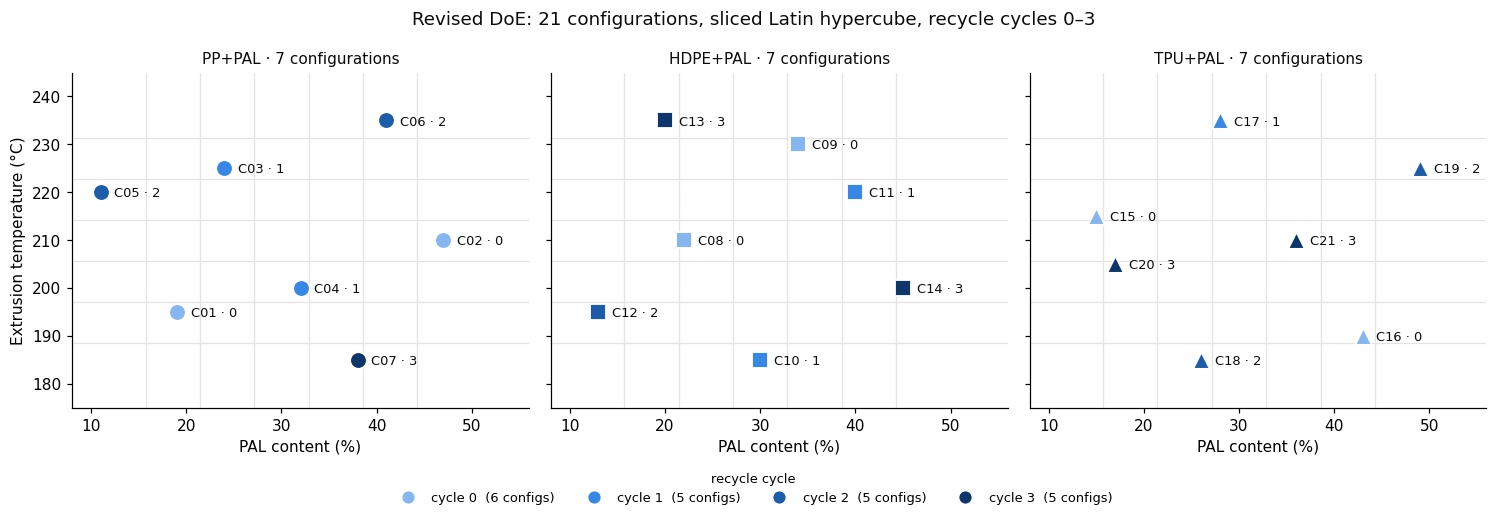

In [10]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_v2_sliced_lhs"

plots.doe_sliced(design, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

**Design space, all polymers together** — the same 21 configurations in one PAL % × temperature panel, one colour and shape per polymer
(PP circle, HDPE square, TPU triangle). The polymers fill each other's gaps, and each band holds one run of every polymer.

In [ ]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_v2_design_space"

plots.doe_design_space(design, title="Configurations in design space",
                       save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

**Pair plot** of the three numeric factors, one colour per polymer. The diagonal counts runs per band for each polymer: exactly one run of
every polymer in each PAL band and each temperature band (on the 5 °C grid), and every polymer at every cycle.

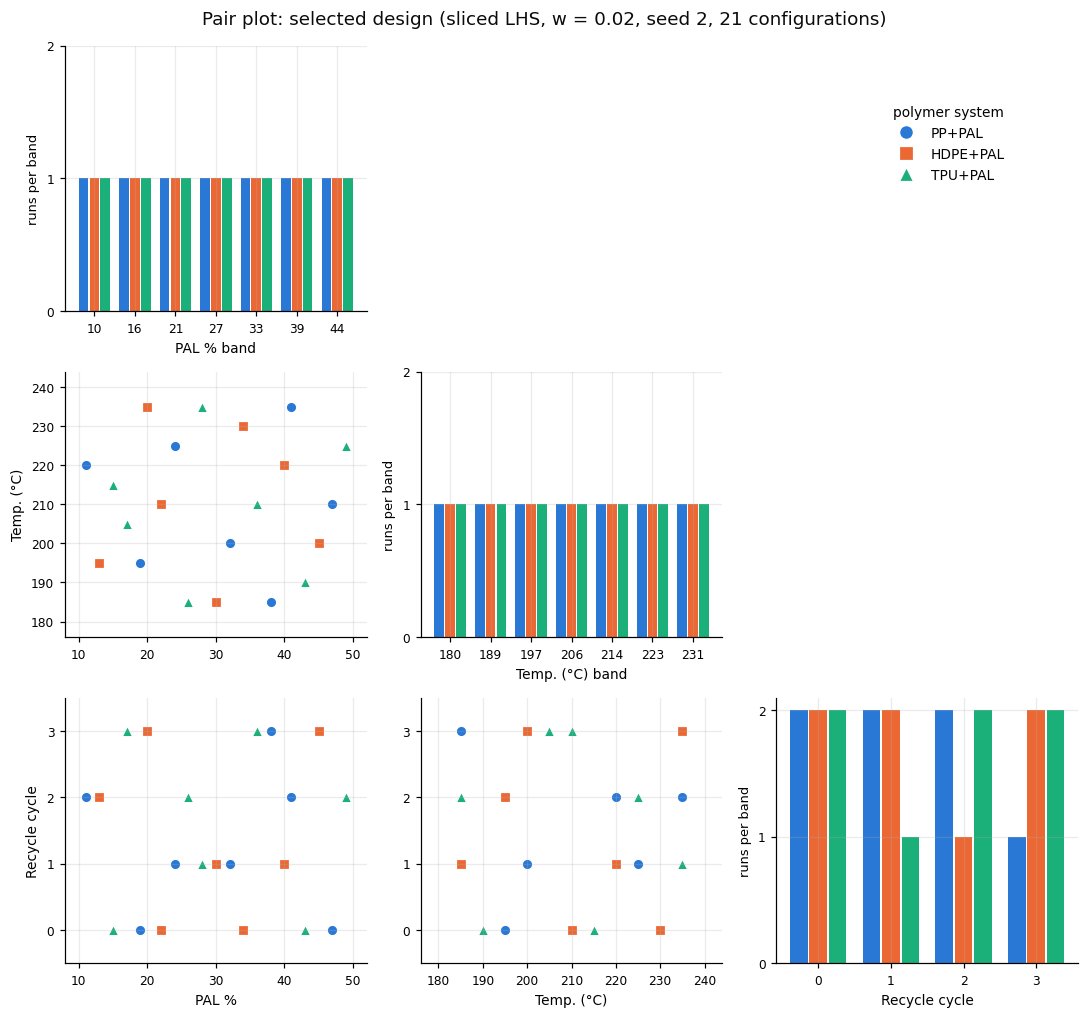

In [11]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_v2_pairs"

plots.doe_pairs(design, title=f"Pair plot: selected design (sliced LHS, w = {PICK[0]:g}, seed {PICK[1]}, {len(design)} configurations)",
                save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

**Correlation** between the numeric factors, for all 21 configurations and within each polymer (closer to 0 = better; check |r| < 0.3,
dotted on the colour bar).

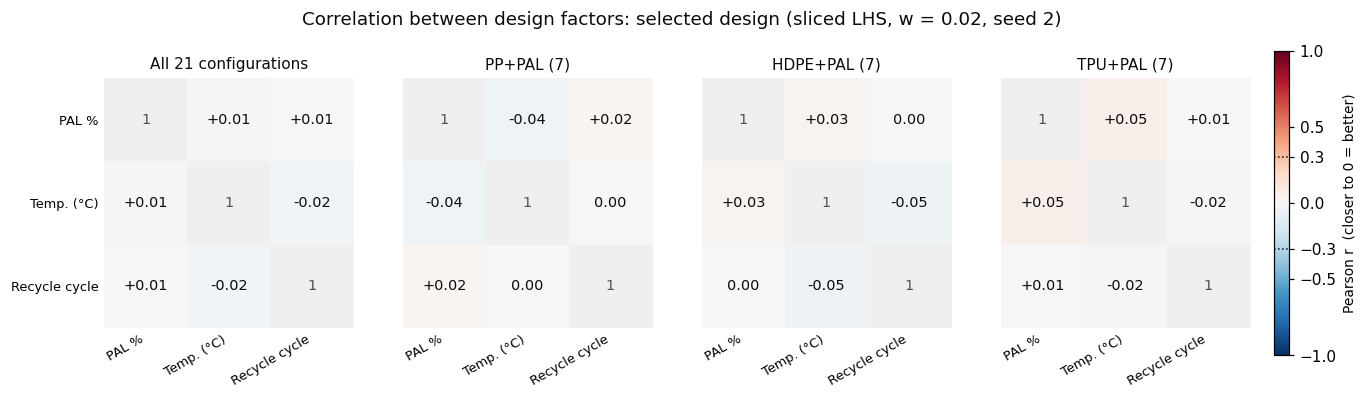

In [12]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_v2_correlation"

plots.doe_correlation(design, title=f"Correlation between design factors: selected design (sliced LHS, w = {PICK[0]:g}, seed {PICK[1]})",
                      save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

---
## 3 — Replicates and the specimen log

**Why 5 and not 3.** The data has n = 3 per configuration, where:

* the IQR fences always enclose all 3 points (Q1 = (a+b)/2, Q3 = (b+c)/2 put the upper fence at or above c), so no point is ever flagged; Dixon's Q
  needs Q > 0.970 at n = 3, i.e. the other two specimens almost identical;
* scaling by the configuration's own SD is bounded (max |studentized residual| = 2/√3 ≈ 1.155), so "noisy configuration" and "one bad specimen"
  look the same, and heteroscedasticity cannot be estimated per configuration;
* dropping one specimen leaves 2.

With 5: within-configuration screening works (Dixon's Q critical value 0.710), the per-configuration variance has 4 degrees of freedom (needed by
the heteroscedastic-noise model), and 4 specimens remain after an exclusion. Previously delivered data (3 replicates) is kept as is and screened on
pooled log-scale residuals.

**Specimen log.** One row per specimen with blanks for the lab: test date, data rate, measured diameter, break location, notes. An odd
specimen is excluded only for a physical reason (slip, break at the grip, defect), and this is where that reason is recorded. The June
Config16 (100 % PP, 200 °C) case shows why: specimens 1–3 vs 4–5 were evidently acquired at different settings.

In [13]:
REPLICATES = 5
log = doe.specimen_log(design, replicates=REPLICATES)
print(f"{len(design)} configurations x {REPLICATES} = {len(log)} tensile specimens · "
      f"{quality['recycling_loops']} recycling loops · {len(design)} formulations to compound")
log.head(7)

21 configurations x 5 = 105 tensile specimens · 30 recycling loops · 21 formulations to compound


,specimen_id,configuration,replicate,polymer_system,PAL_pct,extrusion_temp_C,recycle_cycle,test_date,data_rate_Hz,diameter_mm,break_location,notes
0,C01_1,1,1,PP+PAL,19,195,0,,,,,
1,C01_2,1,2,PP+PAL,19,195,0,,,,,
2,C01_3,1,3,PP+PAL,19,195,0,,,,,
3,C01_4,1,4,PP+PAL,19,195,0,,,,,
4,C01_5,1,5,PP+PAL,19,195,0,,,,,
5,C02_1,2,1,PP+PAL,47,210,0,,,,,
6,C02_2,2,2,PP+PAL,47,210,0,,,,,


---
## 4 — Hand-off workbook

Sheets: `configurations` (one row per configuration, with the replicate count), `specimen_log` (one row per specimen, blanks to fill),
`notes` (definitions and requests to the lab). The August files `doe/doe_formulations.*` / `doe/doe_measurement_plan.*` are left untouched.

In [14]:
SAVE_XLSX = False                     # True -> write doe/<XLSX_NAME>.xlsx
XLSX_NAME = "doe_plan_v2"
SAVE_CSV = False                      # True -> write the configurations to doe/<CSV_NAME>.csv
CSV_NAME = "doe_plan_v2"

configurations = design.assign(tensile_replicates=REPLICATES)
notes = pd.DataFrame({"item": [
    "configuration", "polymer_system", "PAL_pct", "extrusion_temp_C", "recycle_cycle",
    "tensile_replicates", "file names", "specimen_log", "processing window"], "note": [
    "C01-C21; new numbering, independent of the August formulations f01-f12",
    "PP+PAL, HDPE+PAL or TPU+PAL; 7 configurations each",
    "PAL content in %, range 10-50",
    "extrusion temperature in degC, range 180-240, 5 degC grid",
    "0 = as extruded (no recycling); 1-3 = number of recycling loops. We assume every loop uses the configuration's extrusion temperature; please tell us if not",
    "5 tensile specimens per configuration",
    "please name each test file by configuration and replicate, e.g. C07_3",
    "please fill in test date, data rate (Hz), measured diameter (mm), break location (gauge / near grip / in grip) and anything unusual (slip, voids)",
    "if a configuration is outside what a polymer can be processed at, tell us and we will move it"]})

xlsx = io.save_path(p.doe, XLSX_NAME, SAVE_XLSX, ".xlsx")
if xlsx:
    with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
        configurations.to_excel(xw, sheet_name="configurations", index=False)
        log.to_excel(xw, sheet_name="specimen_log", index=False)
        notes.to_excel(xw, sheet_name="notes", index=False)
csv = io.save_path(p.doe, CSV_NAME, SAVE_CSV, ".csv")
if csv:
    configurations.to_csv(csv, index=False)
print("written:", [str(x) for x in (xlsx, csv) if x] or "nothing (switches off)")
configurations

written: nothing (switches off)


,configuration,polymer_system,PAL_pct,extrusion_temp_C,recycle_cycle,tensile_replicates
0,1,PP+PAL,19,195,0,5
1,2,PP+PAL,47,210,0,5
2,3,PP+PAL,24,225,1,5
3,4,PP+PAL,32,200,1,5
4,5,PP+PAL,11,220,2,5
5,6,PP+PAL,41,235,2,5
6,7,PP+PAL,38,185,3,5
7,8,HDPE+PAL,22,210,0,5
8,9,HDPE+PAL,34,230,0,5
9,10,HDPE+PAL,30,185,1,5


---
## Reading the result

* **Coverage.** Every polymer has one run in each of the 7 PAL bands and each of the 7 temperature bands on the lab grid, and every polymer
  covers all 4 cycles (6 / 5 / 5 / 5 configurations at cycles 0 / 1 / 2 / 3). Temperatures span 185–235 °C, PAL 11–49 %.
* **Correlation** ≤ 0.05 overall and within each polymer, so the model can separate degradation from formulation.
* **Cost.** 21 formulations to compound, 30 recycling loops (cycle sum), 105 tensile specimens.
* **Degradation is estimated across formulations**, by the model; no formulation is measured at two cycles. A configuration at cycle 2 or 3
  passes through the lower cycles, so keeping a little material at each intermediate cycle would give within-formulation trajectories
  for extra specimens only, with no extra loops.
* **Earlier data.** The design is new and does not place points around the 12 August formulations. If the September specimens are confirmed
  as cycle 0, those 9 formulations add cycle-0 data on top of this design.